<a href="https://colab.research.google.com/github/lilianam37/deep-minds/blob/main/notebooks/week1/A2_logistic_regression_url.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Hook the Colab up to Drive and set where results and figures get saved
import sys
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')
sys.path.append(str(DATA_DIR))
FIG_DIR = DATA_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
LOG = DATA_DIR / 'results_log.csv'

Mounted at /content/drive


In [ ]:
#Loads the 22 URL-only features and scales them (scaler fit on training rows only)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from project_utils import URL_FEATURES, load_master, get_feature_splits, evaluate_model, log_result

df = load_master(DATA_DIR)
data, scaler = get_feature_splits(df, URL_FEATURES, split_col='split')
X_train, y_train = data['train']
X_val, y_val = data['val']
print('Train', X_train.shape, ' Val', X_val.shape)

Train (165056, 22)  Val (35369, 22)


Converged in 14 iterations
              Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Logistic Regression   val    0.9997        1.0  0.9993 0.9996   0.9998  0.9999                0               11


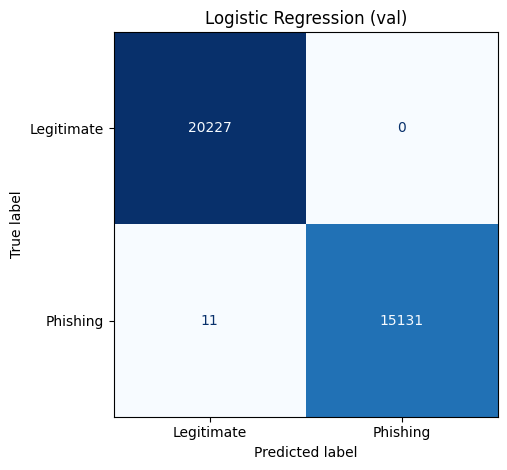

In [ ]:
#Trains the baseline, scoring it on validation, and logs the run
params = dict(C=1.0, penalty='l2', solver='lbfgs', max_iter=1000)
lr = LogisticRegression(**params, random_state=42).fit(X_train, y_train)
print('Converged in', lr.n_iter_[0], 'iterations')

res = evaluate_model('Logistic Regression', 'val', y_val, lr.predict_proba(X_val)[:, 1],
                     save_path=FIG_DIR / 'cm_lr_url_val.png')
log_result(res, {'family': 'LR', 'experiment': 'main', 'features': 'url22', 'split_col': 'split', **params}, LOG)

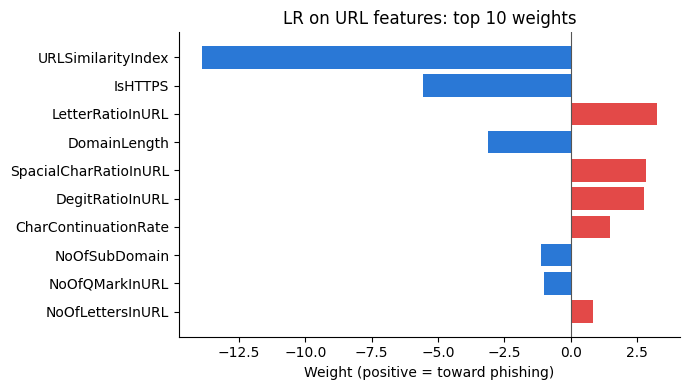

In [ ]:
#Shows which URL features push toward phishing (red) or legitimate (blue)
weights = pd.Series(lr.coef_[0], index=URL_FEATURES)
top = weights.reindex(weights.abs().sort_values(ascending=False).index).head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color=['#e34948' if w > 0 else '#2a78d6' for w in top.values])
ax.axvline(0, color='#555555', lw=0.8)
ax.set_xlabel('Weight (positive = toward phishing)'); ax.set_title('LR on URL features: top 10 weights')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / 'lr_url_top_weights.png', dpi=200); plt.show()